# 11. Evaluación final en test

Entrenamos cada modelo base con datos hasta 2015, ajustamos el método de calibración elegido usando 2016 y evaluamos una sola vez en préstamos con desenlace final de 2017 en adelante. No se reajustan hiperparámetros, características ni calibración a partir de test.

## Advertencia de alcance temporal

La etiqueta disponible en el CSV es el estado final, pero el archivo no documenta la fecha en que ese estado quedó establecido. Los préstamos pueden durar 36 o 60 meses. La tabla de auditoría distingue estados finales y activos por año; si el test tiene muchos préstamos activos, las métricas se refieren solo a la subpoblación con desenlace final y pueden estar sesgadas hacia pagos/incumplimientos tempranos. Los resultados no describen automáticamente todos los préstamos emitidos en esos años.

In [1]:
from pathlib import Path
import sys, json, gc, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, roc_auc_score, average_precision_score, brier_score_loss, log_loss

RAIZ=Path.cwd()
if not (RAIZ/"src").exists(): RAIZ=RAIZ.parent
if str(RAIZ) not in sys.path: sys.path.insert(0,str(RAIZ))
from src import etapas_finales as ef
SALIDA=RAIZ/"outputs"/"evaluacion_final"
SALIDA.mkdir(parents=True,exist_ok=True)
DIR_CAL=RAIZ/"outputs"/"calibracion_probabilidades"
assert (DIR_CAL/"metodos_seleccionados.csv").exists(), "Ejecutar primero el notebook 10."
seleccion=pd.read_csv(DIR_CAL/"metodos_seleccionados.csv")
metodos=dict(zip(seleccion.modelo,seleccion.metodo_seleccionado))
print("Python",platform.python_version(),"pandas",pd.__version__)
print("Métodos fijados antes de mirar test:",metodos)

Python 3.14.0 pandas 3.0.3
Métodos fijados antes de mirar test: {'regresion_logistica': 'Sigmoide', 'svm_lineal': 'Sigmoide', 'gradient_boosting': 'Sigmoide'}


## 1. Auditoría del periodo de prueba

In [2]:
conteos_test,test,candidatas,ruta=ef.auditar_y_cargar_test(verbose=True)
conteos_test.to_csv(SALIDA/"auditoria_estados_test.csv",index=False,encoding="utf-8-sig")
print("Archivo:",ruta)
print("Estados de todos los préstamos emitidos desde 2017, incluidos los activos:")
print(conteos_test.to_string(index=False))
print("\nPréstamos con desenlace final que entrarán a métricas:",f"{len(test):,}")
print("Años evaluados:",sorted(test.anio.unique()))
print("Distribución de plazo y desenlace final:")
if "term" in test: print(test.groupby(["anio","term","loan_status"],observed=True).size().rename("prestamos").to_string())
print("\nPrevalencia por año en la muestra finalizada:")
print(test.groupby("anio").default.agg(["size","mean"]).to_string())
print("Aviso: el archivo no incluye fecha individual de maduración del desenlace; los estados finales no permiten reconstruir cuándo fueron conocidos.")

Auditoría de test: bloque 10 recorrido.
Archivo: C:\Users\josue\Downloads\accepted_2007_to_2018Q4.csv.gz
Estados de todos los préstamos emitidos desde 2017, incluidos los activos:
 anio        loan_status  prestamos
 2017            Current     261851
 2017         Fully Paid     130152
 2017        Charged Off      39148
 2017 Late (31-120 days)       8004
 2017    In Grace Period       2911
 2017  Late (16-30 days)       1492
 2017            Default         21
 2018            Current     427181
 2018         Fully Paid      47444
 2018        Charged Off       8867
 2018 Late (31-120 days)       7221
 2018    In Grace Period       2919
 2018  Late (16-30 days)       1603
 2018            Default          7

Préstamos con desenlace final que entrarán a métricas: 225,611
Años evaluados: [np.int16(2017), np.int16(2018)]
Distribución de plazo y desenlace final:
anio  term  loan_status
2017  36.0  Charged Off     25721
            Fully Paid     102817
      60.0  Charged Off     13427


## 2. Entrenamiento base, calibración 2016 y evaluación única

In [3]:
datos_dev,candidatas_dev,_=ef.cargar_desarrollo(ultimo_anio=2016,verbose=True)
assert candidatas_dev==candidatas
metricas_test,pred_test=ef.entrenar_final_y_evaluar(datos_dev,candidatas,test,metodos)
metricas_test.to_csv(SALIDA/"metricas_finales_test.csv",index=False,encoding="utf-8-sig")
pred_test.to_csv(SALIDA/"predicciones_test.csv.gz",index=False,compression="gzip",encoding="utf-8-sig")
print("Configuración final: base <=2015; calibración 2016; test >=2017.")
print(metricas_test.round(5).to_string(index=False))

Bloques leídos: 10; filas fuente recorridas: 1,000,000
Bloques leídos: 20; filas fuente recorridas: 2,000,000
Configuración final: base <=2015; calibración 2016; test >=2017.
             modelo   metodo  variables_originales  columnas_transformadas  anio_base_hasta  anio_calibracion anios_test  ROC_AUC  PR_AUC  Brier_Score  Log_Loss  prevalencia      n
regresion_logistica Sigmoide                    60                     136             2015              2016  2017,2018  0.69259 0.36039      0.15591   0.48501      0.21282 225611
         svm_lineal Sigmoide                    60                     136             2015              2016  2017,2018  0.69178 0.35988      0.15597   0.48680      0.21282 225611
  gradient_boosting Sigmoide                    60                     136             2015              2016  2017,2018  0.70321 0.37791      0.15364   0.47428      0.21282 225611


## 3. Intervalos de confianza por remuestreo

In [4]:
# Bootstrap no paramétrico estratificado por clase, 200 repeticiones. El test
# se usa solo para cuantificar incertidumbre, nunca para elegir configuración.
rng=np.random.default_rng(ef.SEMILLA)
B=200
intervalos=[]
for modelo in ["regresion_logistica","svm_lineal","gradient_boosting"]:
    p=pred_test[modelo].to_numpy(); yt=pred_test.default.to_numpy()
    idx0=np.flatnonzero(yt==0); idx1=np.flatnonzero(yt==1)
    vals={m:[] for m in ["ROC_AUC","PR_AUC","Brier_Score","Log_Loss"]}
    for _ in range(B):
        idx=np.concatenate([rng.choice(idx0,len(idx0),replace=True),rng.choice(idx1,len(idx1),replace=True)])
        yy=yt[idx]; pp=p[idx]
        vals["ROC_AUC"].append(roc_auc_score(yy,pp))
        vals["PR_AUC"].append(average_precision_score(yy,pp))
        vals["Brier_Score"].append(brier_score_loss(yy,pp))
        vals["Log_Loss"].append(log_loss(yy,pp,labels=[0,1]))
    for metrica,arr in vals.items():
        lo,hi=np.quantile(arr,[.025,.975])
        intervalos.append({"modelo":modelo,"metrica":metrica,"IC95_inferior":lo,"IC95_superior":hi,"repeticiones":B})
intervalos=pd.DataFrame(intervalos)
intervalos.to_csv(SALIDA/"intervalos_bootstrap_95.csv",index=False,encoding="utf-8-sig")
print(intervalos.round(5).to_string(index=False))

             modelo     metrica  IC95_inferior  IC95_superior  repeticiones
regresion_logistica     ROC_AUC        0.68964        0.69513           200
regresion_logistica      PR_AUC        0.35705        0.36446           200
regresion_logistica Brier_Score        0.15539        0.15647           200
regresion_logistica    Log_Loss        0.48337        0.48684           200
         svm_lineal     ROC_AUC        0.68904        0.69483           200
         svm_lineal      PR_AUC        0.35654        0.36347           200
         svm_lineal Brier_Score        0.15542        0.15645           200
         svm_lineal    Log_Loss        0.48480        0.48859           200
  gradient_boosting     ROC_AUC        0.70086        0.70593           200
  gradient_boosting      PR_AUC        0.37463        0.38223           200
  gradient_boosting Brier_Score        0.15312        0.15413           200
  gradient_boosting    Log_Loss        0.47281        0.47551           200


## 4. Gráficos comparativos

Figuras guardadas en C:\Users\josue\Proyecto-ML-Grupo8\outputs\evaluacion_final


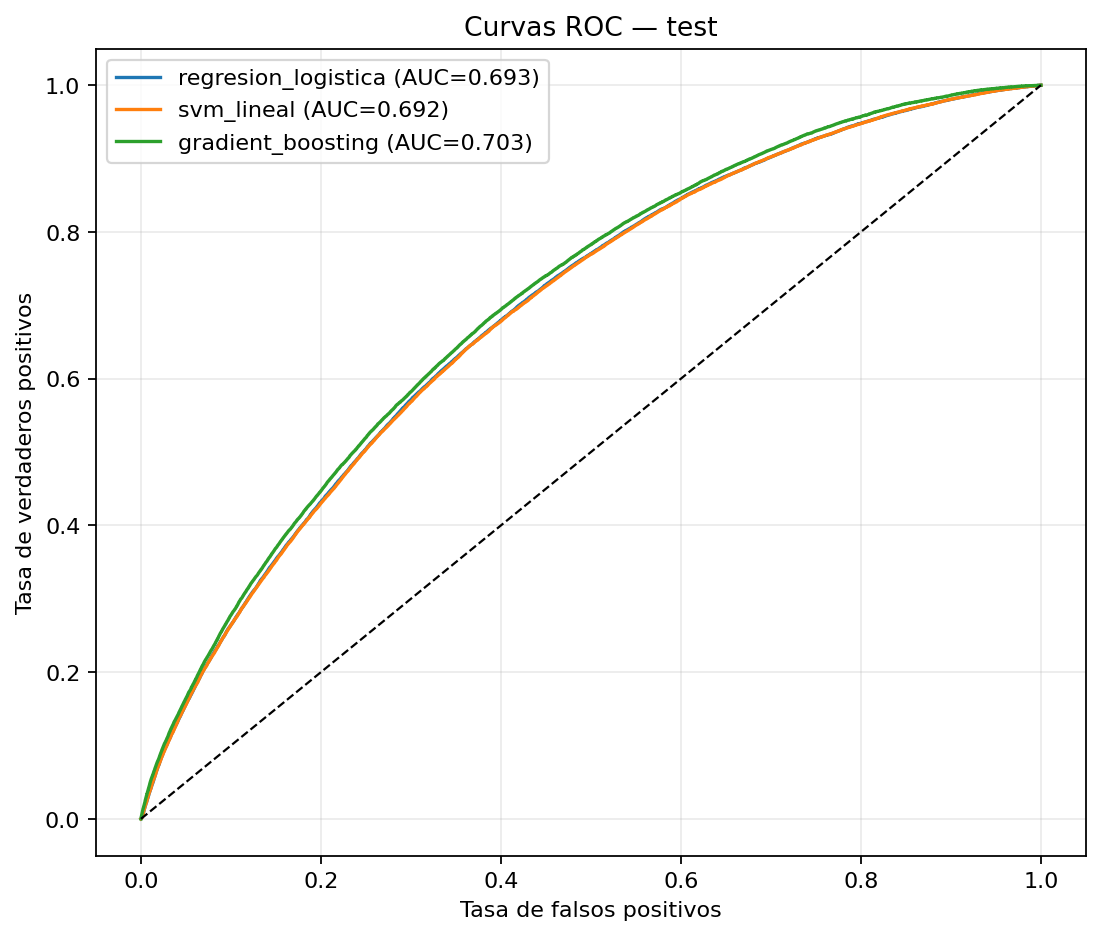

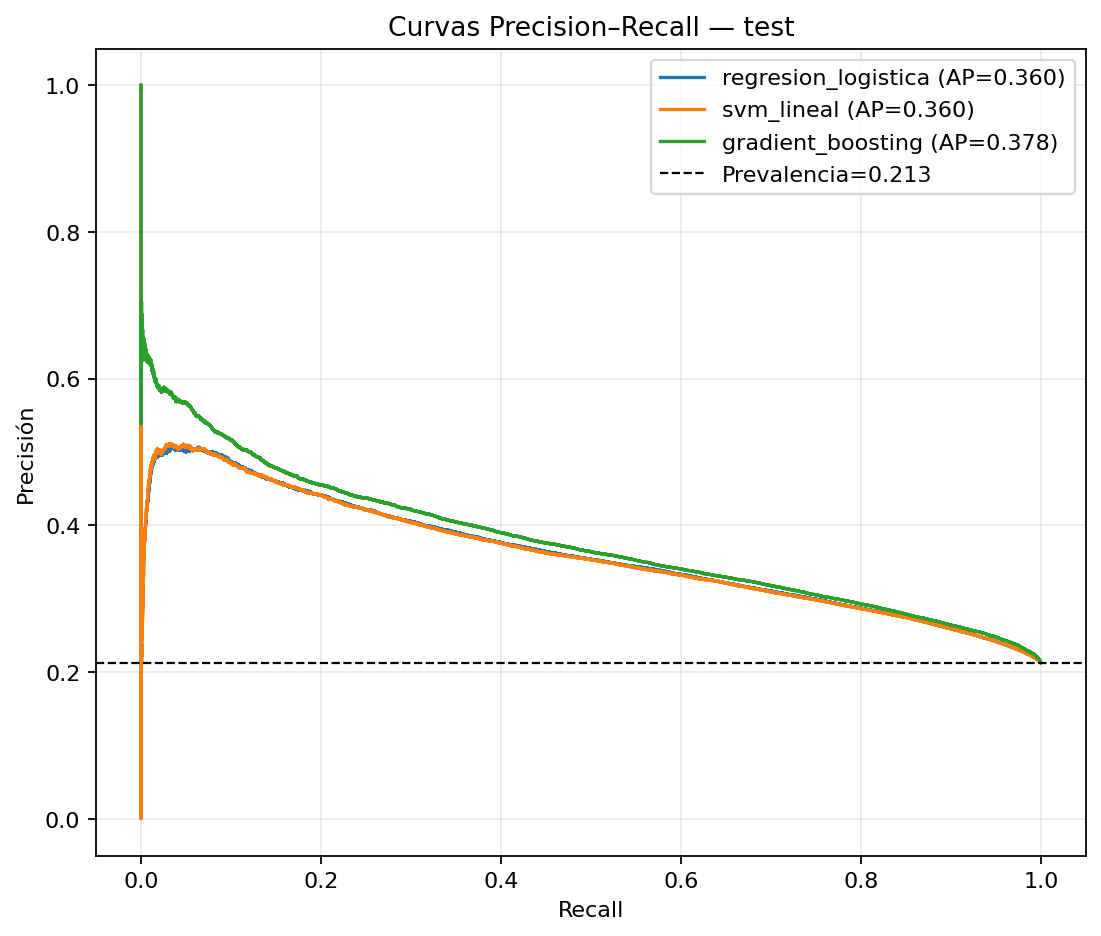

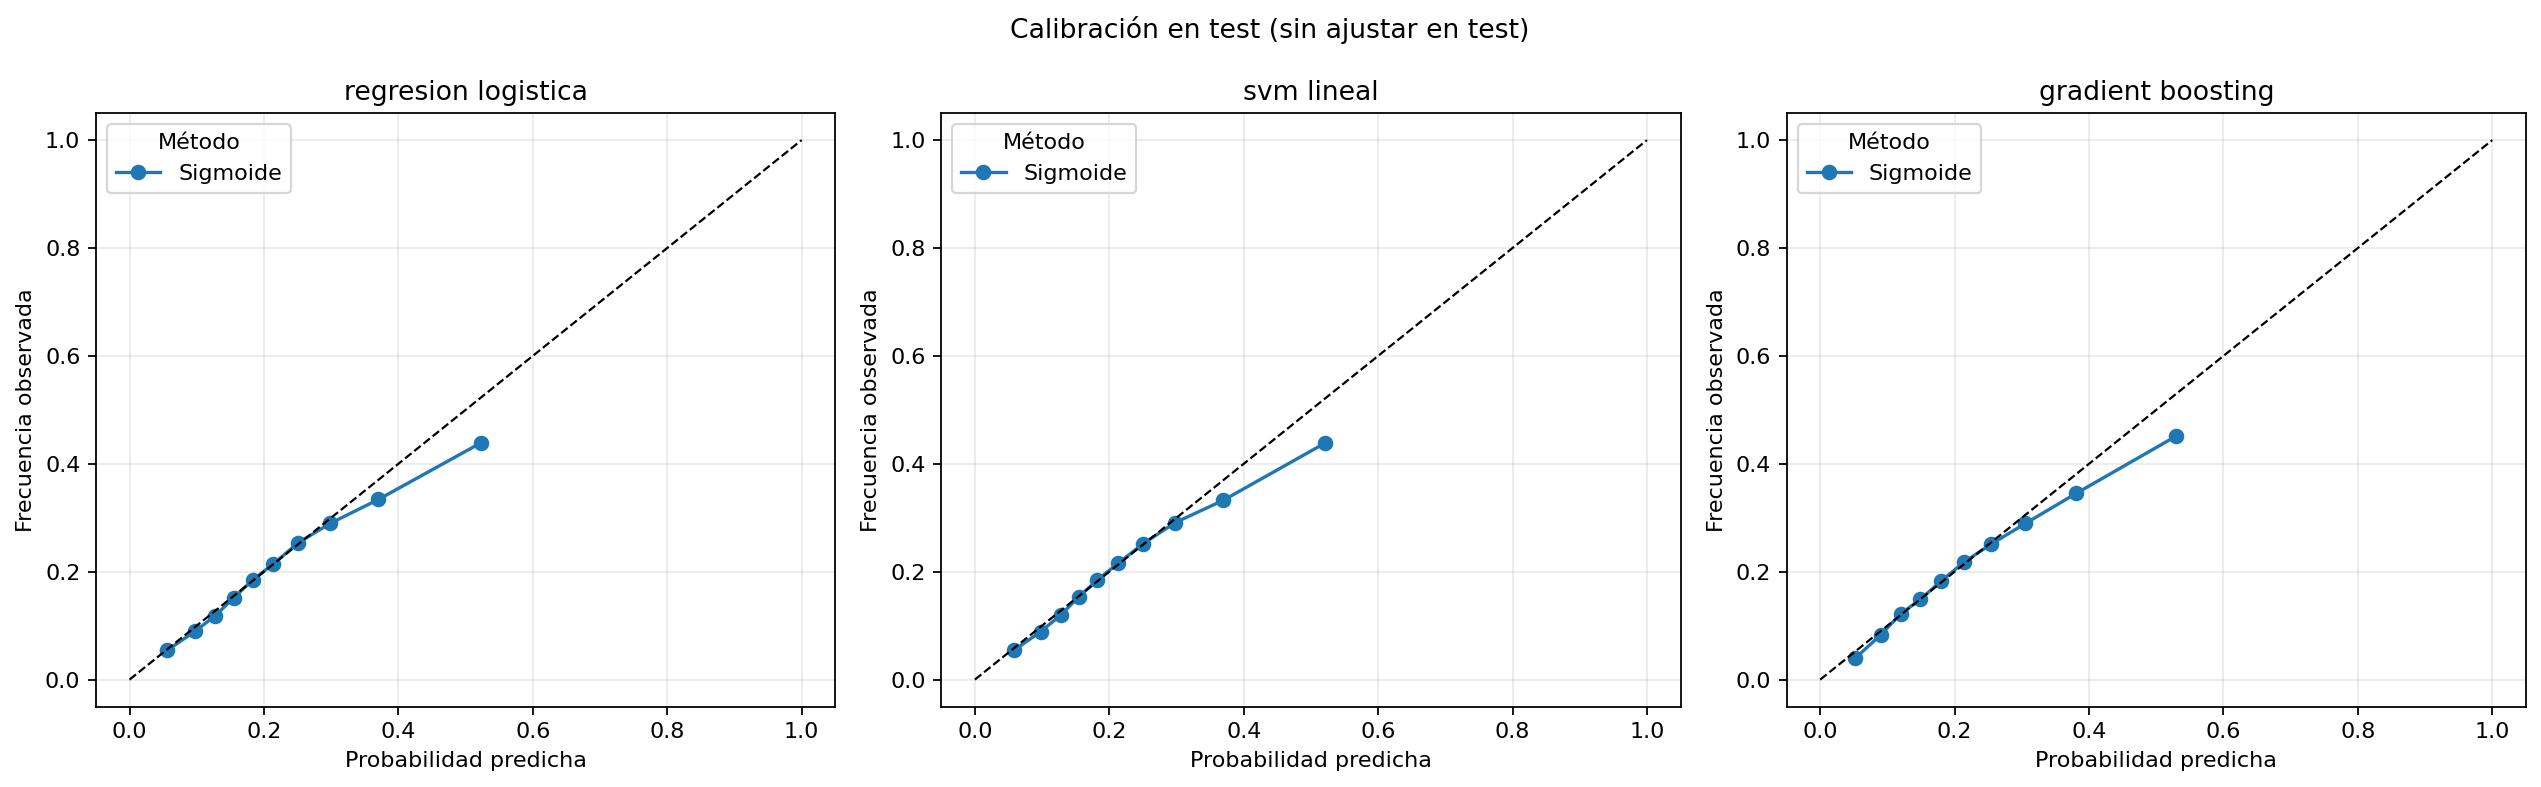

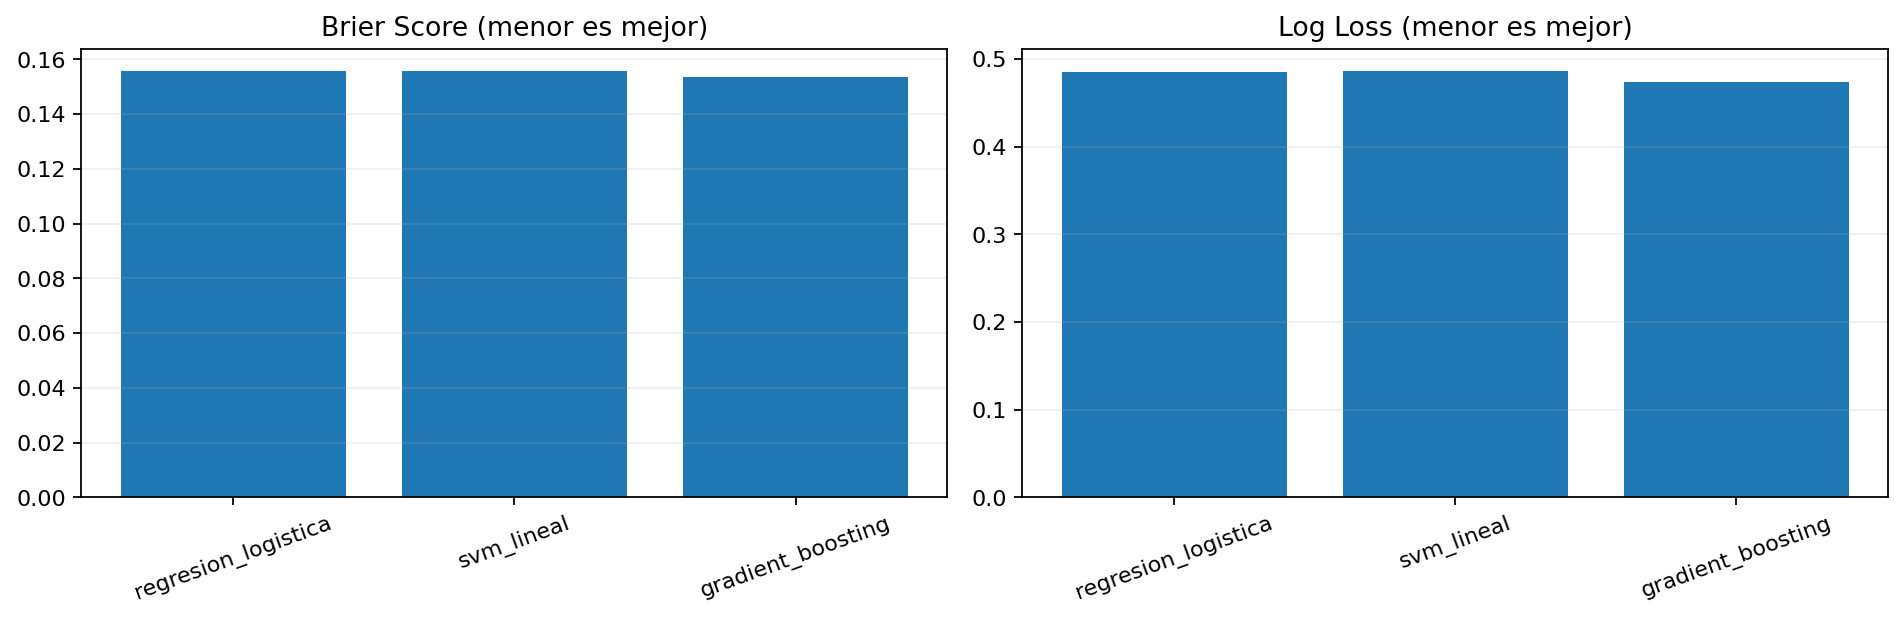

In [5]:
fig,ax=plt.subplots(figsize=(7,6))
for modelo in ["regresion_logistica","svm_lineal","gradient_boosting"]:
    yt=pred_test.default.to_numpy(); pp=pred_test[modelo].to_numpy()
    fpr,tpr,_=roc_curve(yt,pp); ax.plot(fpr,tpr,label=f"{modelo} (AUC={roc_auc_score(yt,pp):.3f})")
ax.plot([0,1],[0,1],"k--",lw=1); ax.set(xlabel="Tasa de falsos positivos",ylabel="Tasa de verdaderos positivos",title="Curvas ROC — test")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(SALIDA/"01_curvas_roc_test.png",dpi=160,bbox_inches="tight"); plt.close(fig)

fig,ax=plt.subplots(figsize=(7,6))
for modelo in ["regresion_logistica","svm_lineal","gradient_boosting"]:
    yt=pred_test.default.to_numpy(); pp=pred_test[modelo].to_numpy()
    precision,recall,_=precision_recall_curve(yt,pp); ax.plot(recall,precision,label=f"{modelo} (AP={average_precision_score(yt,pp):.3f})")
ax.axhline(pred_test.default.mean(),color="k",linestyle="--",lw=1,label=f"Prevalencia={pred_test.default.mean():.3f}")
ax.set(xlabel="Recall",ylabel="Precisión",title="Curvas Precision–Recall — test"); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(SALIDA/"02_curvas_precision_recall_test.png",dpi=160,bbox_inches="tight"); plt.close(fig)

from sklearn.calibration import calibration_curve
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,modelo in zip(axes,["regresion_logistica","svm_lineal","gradient_boosting"]):
    frac,mean=calibration_curve(pred_test.default,pred_test[modelo],n_bins=10,strategy="quantile")
    ax.plot(mean,frac,marker="o",label=metodos[modelo]); ax.plot([0,1],[0,1],"k--",lw=1)
    ax.set(title=modelo.replace("_"," "),xlabel="Probabilidad predicha",ylabel="Frecuencia observada"); ax.grid(alpha=.25); ax.legend(title="Método")
fig.suptitle("Calibración en test (sin ajustar en test)"); fig.tight_layout(); fig.savefig(SALIDA/"03_calibracion_test.png",dpi=160,bbox_inches="tight"); plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,title in [(axes[0],"Brier_Score","Brier Score (menor es mejor)"),(axes[1],"Log_Loss","Log Loss (menor es mejor)")]:
    ax.bar(metricas_test.modelo,metricas_test[metric]); ax.set_title(title); ax.tick_params(axis="x",rotation=20); ax.grid(axis="y",alpha=.2)
fig.tight_layout(); fig.savefig(SALIDA/"04_calidad_probabilidades_test.png",dpi=160,bbox_inches="tight"); plt.close(fig)
print("Figuras guardadas en",SALIDA)

## 5. Validación frente a test e interpretación

In [6]:
validacion=pd.read_csv(DIR_CAL/"metricas_por_modelo_metodo_anio.csv")
filas=[]
for r in metricas_test.itertuples():
    v=validacion[(validacion.modelo==r.modelo)&(validacion.metodo==r.metodo)]
    filas.append({"modelo":r.modelo,"metodo":r.metodo,"ROC_AUC_validacion_media":v.ROC_AUC.mean(),
                  "PR_AUC_validacion_media":v.PR_AUC.mean(),"Brier_validacion_medio":v.Brier_Score.mean(),
                  "LogLoss_validacion_medio":v.Log_Loss.mean(),"ROC_AUC_test":r.ROC_AUC,
                  "PR_AUC_test":r.PR_AUC,"Brier_test":r.Brier_Score,"LogLoss_test":r.Log_Loss})
comparacion=pd.DataFrame(filas)
comparacion.to_csv(SALIDA/"comparacion_validacion_test.csv",index=False,encoding="utf-8-sig")
print(comparacion.round(5).to_string(index=False))
print("\nTest n=",len(pred_test),"| años=",sorted(pred_test.anio.unique()),"| prevalencia=",round(pred_test.default.mean(),5))
print("Métodos fijados antes de test:",metodos)
print("\nConclusión automática para orientar la lectura; no se cambia ningún modelo:")
for r in metricas_test.sort_values("ROC_AUC",ascending=False).itertuples():
    print(f"{r.modelo}: ROC-AUC={r.ROC_AUC:.4f}; AP={r.PR_AUC:.4f}; Brier={r.Brier_Score:.4f}; Log Loss={r.Log_Loss:.4f}; método={r.metodo}.")
print("La mejor ROC-AUC identifica mejor ordenamiento, no garantiza probabilidades más precisas. Revisar Brier, Log Loss y curvas.")

             modelo   metodo  ROC_AUC_validacion_media  PR_AUC_validacion_media  Brier_validacion_medio  LogLoss_validacion_medio  ROC_AUC_test  PR_AUC_test  Brier_test  LogLoss_test
regresion_logistica Sigmoide                   0.69164                  0.34539                 0.14410                   0.45481       0.69259      0.36039     0.15591       0.48501
         svm_lineal Sigmoide                   0.69141                  0.34446                 0.14414                   0.45473       0.69178      0.35988     0.15597       0.48680
  gradient_boosting Sigmoide                   0.69736                  0.35198                 0.14313                   0.45097       0.70321      0.37791     0.15364       0.47428

Test n= 225611 | años= [np.int16(2017), np.int16(2018)] | prevalencia= 0.21282
Métodos fijados antes de test: {'regresion_logistica': 'Sigmoide', 'svm_lineal': 'Sigmoide', 'gradient_boosting': 'Sigmoide'}

Conclusión automática para orientar la lectura; no se cambia 

## 6. Cierre y límites

Las métricas finales describen únicamente préstamos de 2017 en adelante que ya aparecen con estado `Fully Paid` o `Charged Off` en el archivo. Los estados activos se muestran en la auditoría, pero no se inventa su desenlace ni se les asigna una etiqueta. Debido a que el archivo no aporta la fecha de cierre individual, no se puede comprobar maduración completa ni reconstruir qué etiquetas estaban disponibles en cada fecha histórica. No se reajustaron configuraciones, umbrales ni calibradores con el test.

Salidas: `outputs/evaluacion_final/`; el notebook 10 conserva selección de calibración y métricas de validación.

## 7. Registro reproducible de la evaluación

Se guardan parámetros, cortes, métodos ya elegidos y versión de las bibliotecas junto a las métricas finales.


In [7]:
import importlib.metadata as package_metadata
from datetime import datetime
metricas_guardadas=pd.read_csv(SALIDA/"metricas_finales_test.csv")
seleccion_guardada=pd.read_csv(DIR_CAL/"metodos_seleccionados.csv")
config_final={
 "parametros_modelos":ef.PARAMETROS,
 "configuracion_calibrador_sigmoide":{"implementacion":"Platt con LogisticRegression","C":1e6,"solver":"lbfgs","max_iter":2000,"random_state":int(ef.SEMILLA)},
 "configuracion_calibrador_isotonico":{"out_of_bounds":"clip","y_min":0,"y_max":1},
 "metodos_calibracion":dict(zip(seleccion_guardada.modelo,seleccion_guardada.metodo_seleccionado)),
 "base_modelo_hasta":2015,"calibracion_en":2016,"test_desde":2017,
 "umbral_faltantes_train_pct":ef.UMBRAL_FALTANTES,"indicadores_faltantes":False,
 "semilla":int(ef.SEMILLA),"python":platform.python_version(),
 "pandas":pd.__version__,"numpy":np.__version__,
 "scikit_learn":package_metadata.version("scikit-learn"),
 "n_test_con_etiqueta_binaria":int(metricas_guardadas.n.iloc[0]),
 "prevalencia_test":float(metricas_guardadas.prevalencia.iloc[0]),
 "test_anos":metricas_guardadas.anios_test.iloc[0],
 "fecha_ejecucion_local":datetime.now().isoformat(timespec="seconds"),
 "limitacion":"Solo Fully Paid/Charged Off; estados finales no revelan fecha de maduración."
}
(SALIDA/"configuracion_final.json").write_text(json.dumps(config_final,ensure_ascii=False,indent=2),encoding="utf-8")
print("Configuración final guardada en",SALIDA/"configuracion_final.json")
print(json.dumps(config_final,ensure_ascii=False,indent=2))

Configuración final guardada en outputs\evaluacion_final\configuracion_final.json
{
  "parametros_modelos": {
    "regresion_logistica": {
      "C": 0.03148911647956861,
      "class_weight": null,
      "tol": 8.66211944751964e-05
    },
    "svm_lineal": {
      "C": 0.010053940194693016,
      "class_weight": "balanced",
      "tol": 0.0001
    },
    "gradient_boosting": {
      "learning_rate": 0.05279087869966013,
      "max_iter": 200,
      "max_leaf_nodes": 25,
      "min_samples_leaf": 31,
      "l2_regularization": 9.149845592811953
    }
  },
  "configuracion_calibrador_sigmoide": {
    "implementacion": "Platt con LogisticRegression",
    "C": 1000000.0,
    "solver": "lbfgs",
    "max_iter": 2000,
    "random_state": 42
  },
  "configuracion_calibrador_isotonico": {
    "out_of_bounds": "clip",
    "y_min": 0,
    "y_max": 1
  },
  "metodos_calibracion": {
    "regresion_logistica": "Sigmoide",
    "svm_lineal": "Sigmoide",
    "gradient_boosting": "Sigmoide"
  },
  "bas